# Pruebas de Qutip

Primero intentaremos determinar la mecánica de un sistema de 3 átomos de dos niveles con el Hamiltoniano de Tavis-Cumming

$$H =\hat{a}^\dagger\hat{a} + \frac{\epsilon}{2}J_z + \frac{\lambda}{2\sqrt{N}}(\hat{a} J_+ + \hat{a}^\dagger J_-)$$

Usaremos la aproximación de onda contrarrotante por simplicidad.

In [33]:
from qutip import *
import numpy as np
import matplotlib.pyplot as plt

Primero definimos nuestras variables principales, tomaremos un sistema con 4 excitaciones. Truncaremos además el espacio de Hilbert a un máximo de 10 fotones.

In [34]:
N_cav = 20 #(truncado)
N_atomos = 5
epsilon = 1
lamda = 1
g = lamda / (2*np.sqrt(N_atomos)) # Acoplamiento

tiempo = 100
pasos = 400
a = tensor([destroy(N_cav)] + [qeye(2) for _ in range(0,  N_atomos)])

#Definimos a la lista de los operadores individuales:
sigmaz_list = [tensor([qeye(N_cav)] + [sigmaz() if j == i else qeye(2) for j in range(N_atomos)]) for i in range(N_atomos)]
sigmam_list = [tensor([qeye(N_cav)] + [sigmam() if j == i else qeye(2) for j in range(N_atomos)]) for i in range(N_atomos)]
sigmap_list = [tensor([qeye(N_cav)] + [sigmap() if j == i else qeye(2) for j in range(N_atomos)]) for i in range(N_atomos)]

#Ahora definimos a los operadores colectivos
J_z = sum(sigmaz_list)
J_m = sum(sigmam_list)
J_p = J_m.dag()

Ahora definimos nuestro Hamiltoniano, resolveremos la dinámica del sistema con ```mesolve``` el cual resuelve la ecuación maestra de Lindblad si se le proveen términos disipativos, como en este caso no se le darán, se introduce el estado inicial en forma de matriz de densidad, por lo se simplifica a la ecuación de von Neumann

In [35]:
H = a.dag() * a + (epsilon/2) * J_z + (g/2) * (a * J_p + a.dag() * J_m)

tlist = np.linspace(0, tiempo, pasos)

estado_inicial = tensor([basis(N_cav, 0)] + [basis(2,0) for _ in range(N_atomos)])
rho0 = ket2dm(estado_inicial)


Ahora graficamos los resultados para ambos valores esperados:

Text(0, 0.5, '$\\left< n \\right>$')

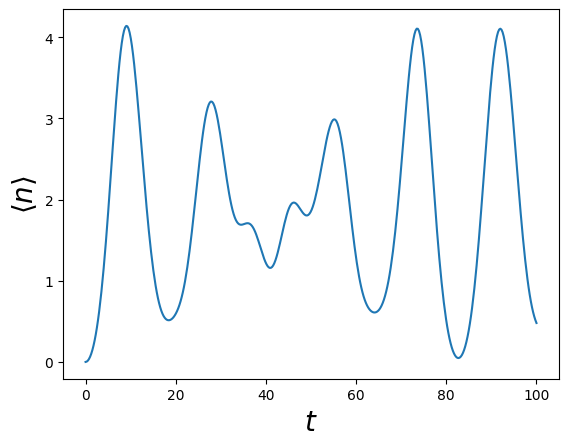

In [36]:
result = mesolve(H, rho0, tlist, c_ops=[], e_ops=[a.dag()*a, J_z])

fig1, axes1 = plt.subplots(1, 1)

axes1.plot(tlist, result.expect[0] )

axes1.set_xlabel(r"$t$", fontsize=20)
axes1.set_ylabel(r"$\left< n \right>$", fontsize=20)

Text(0, 0.5, '$\\left< J_z \\right>$')

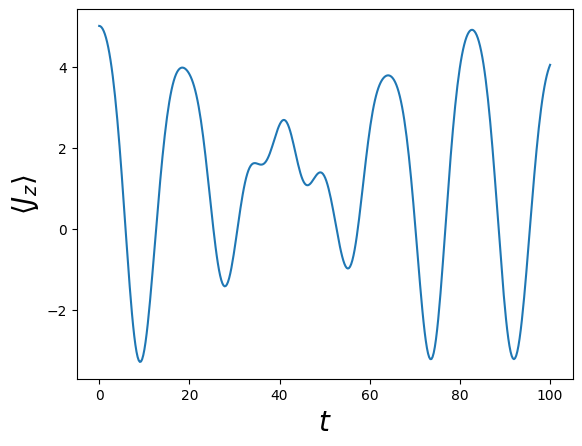

In [37]:
fig2, axes2 = plt.subplots(1, 1)

axes2.plot(tlist, result.expect[1])
axes2.set_xlabel(r"$t$", fontsize=20)
axes2.set_ylabel(r"$\left< J_z \right>$", fontsize=20)


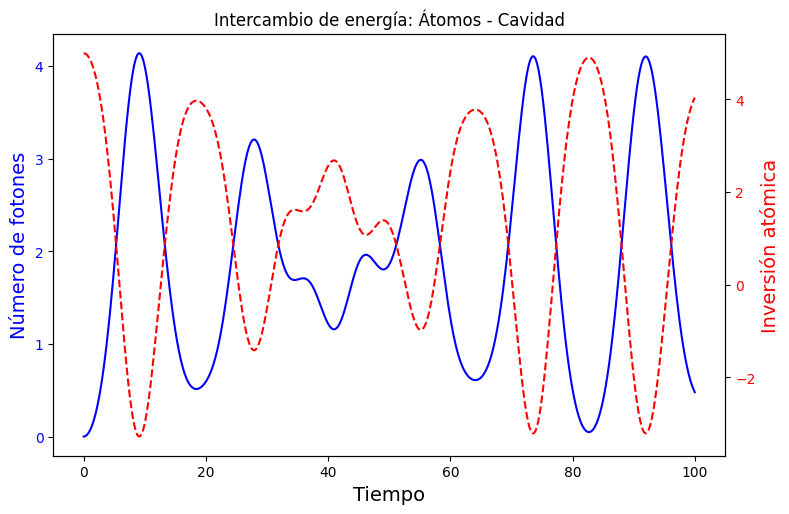

In [38]:
# Extraer resultados
n_fotones = result.expect[0]
valor_jz = result.expect[1]

# Graficar
fig, ax1 = plt.subplots(figsize=(8, 5))

# Eje para fotones
ax1.plot(tlist, n_fotones, 'b-', label=r"$\langle n \rangle$ (Fotones)")
ax1.set_xlabel("Tiempo", fontsize=14)
ax1.set_ylabel("Número de fotones", color='b', fontsize=14)
ax1.tick_params(axis='y', labelcolor='b')

# Eje espejo para Jz
ax2 = ax1.twinx()
ax2.plot(tlist, valor_jz, 'r--', label=r"$\langle J_z \rangle$ (Inversión)")
ax2.set_ylabel("Inversión atómica", color='r', fontsize=14)
ax2.tick_params(axis='y', labelcolor='r')

fig.tight_layout()
plt.title("Intercambio de energía: Átomos - Cavidad")
plt.show()

Veamos la transición de fase cuántica, esta depende del acoplamiento $\lambda$, el cual variaremos para ver si dado un valor crítico es que las propiedades cambian.

Observaremos el parámetro de orden $\frac{\langle \hat{a}^\dagger \hat{a}\rangle}{N_{atomos}}$ 

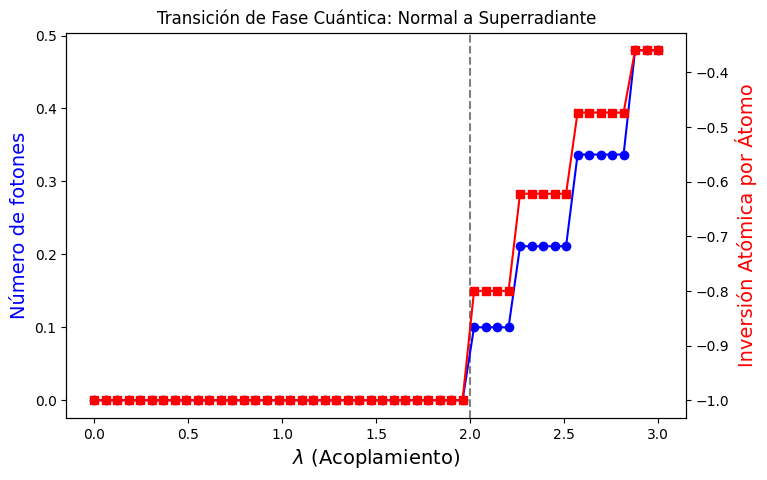

In [39]:

lamdas = np.linspace(0, 3, 50) # Rango de acoplamiento (debe cruzar lambda_c)

# Parte del Hamiltoniano que no depende de lambda
H0 = a.dag() * a + (epsilon / 2) * J_z

n_fotones = []
inversion = []

for l in lamdas:
    g_eff = l / (2 * np.sqrt(N_atomos))
    H = H0 + g_eff * (a * J_p + a.dag() * J_m)
    
    # Calculamos el estado fundamental (energía y ket)
    en, gs = H.groundstate()
    
    # Guardamos los valores esperados en el estado fundamental
    n_fotones.append(expect(a.dag() * a, gs)/N_atomos)
    inversion.append(expect(J_z, gs) / N_atomos)

fig, ax1 = plt.subplots(figsize=(8, 5))

# Punto crítico teórico para el modelo de Dicke/Tavis-Cummings
lambda_c = 2* np.sqrt(epsilon) 
ax1.axvline(lambda_c, color='gray', linestyle='--', label='Punto Crítico')

ax1.plot(lamdas, n_fotones, 'bo-', label='Fotones')
ax1.set_xlabel(r'$\lambda$ (Acoplamiento)', fontsize=14)
ax1.set_ylabel('Número de fotones', color='b', fontsize=14)

ax2 = ax1.twinx()
ax2.plot(lamdas, inversion, 'rs-', label='Inversión (Jz/N)')
ax2.set_ylabel('Inversión Atómica por Átomo', color='r', fontsize=14)

plt.title("Transición de Fase Cuántica: Normal a Superradiante")
plt.show()

Agregamos nuestro primer término disipativo al hamiltoniano, el cual agregamos en la opción de ```c_ops``` en la función ```msolve``` y graficamos los valores esperados de $J_z$ y $\hat{a}^\dagger \hat{a}$ el término disipativo es $\sqrt{\kappa} \hat{a}$


In [40]:
kappa = 0.05 #razón de relajación.

result = mesolve(H, rho0, tlist, c_ops=[np.sqrt(kappa) * a], e_ops=[a.dag() * a, J_z], options={"store_states": True})

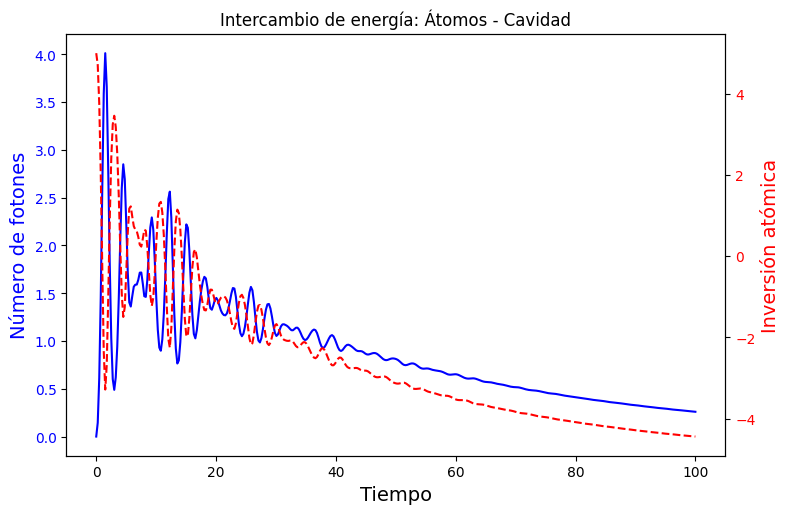

In [41]:
# Extraer resultados
n_fotones = result.expect[0]
valor_jz = result.expect[1]

# Graficar
fig, ax1 = plt.subplots(figsize=(8, 5))

# Eje para fotones
ax1.plot(tlist, n_fotones, 'b-', label=r"$\langle n \rangle$ (Fotones)")
ax1.set_xlabel("Tiempo", fontsize=14)
ax1.set_ylabel("Número de fotones", color='b', fontsize=14)
ax1.tick_params(axis='y', labelcolor='b')

# Eje espejo para Jz
ax2 = ax1.twinx()
ax2.plot(tlist, valor_jz, 'r--', label=r"$\langle J_z \rangle$ (Inversión)")
ax2.set_ylabel("Inversión atómica", color='r', fontsize=14)
ax2.tick_params(axis='y', labelcolor='r')

fig.tight_layout()
plt.title("Intercambio de energía: Átomos - Cavidad")
plt.show()

También podemos agregar más términos al hemiltoniano, convirtiendolo en el modelo de Dicke


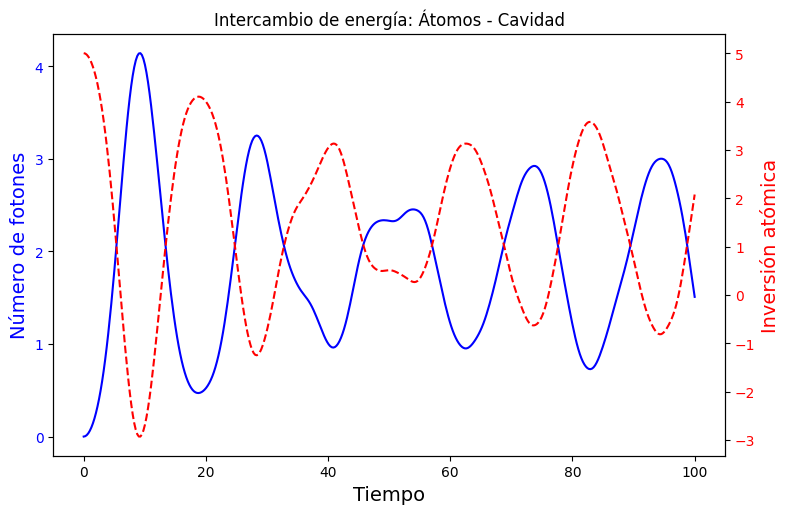

In [42]:
H = a.dag() * a + (epsilon/2) * J_z + (g/2) * (a  + a.dag()) * (J_p + J_m)
result = mesolve(H, rho0, tlist, c_ops=[], e_ops=[a.dag() * a, J_z], options={"store_states": True})
# Extraer resultados
n_fotones = result.expect[0]
valor_jz = result.expect[1]

# Graficar
fig, ax1 = plt.subplots(figsize=(8, 5))

# Eje para fotones
ax1.plot(tlist, n_fotones, 'b-', label=r"$\langle n \rangle$ (Fotones)")
ax1.set_xlabel("Tiempo", fontsize=14)
ax1.set_ylabel("Número de fotones", color='b', fontsize=14)
ax1.tick_params(axis='y', labelcolor='b')

# Eje espejo para Jz
ax2 = ax1.twinx()
ax2.plot(tlist, valor_jz, 'r--', label=r"$\langle J_z \rangle$ (Inversión)")
ax2.set_ylabel("Inversión atómica", color='r', fontsize=14)
ax2.tick_params(axis='y', labelcolor='r')

fig.tight_layout()
plt.title("Intercambio de energía: Átomos - Cavidad")
plt.show()

Ahora le podemos agregar términos disipativos y calcular los mismos valores esperados.

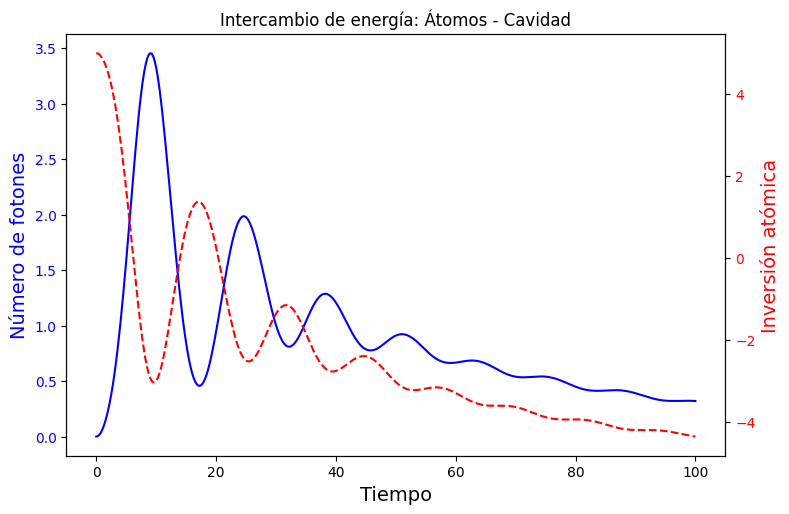

In [43]:
result = mesolve(H, rho0, tlist, c_ops=[np.sqrt(kappa) * a], e_ops=[a.dag() * a, J_z], options={"store_states": True})
# Extraer resultados
n_fotones = result.expect[0]
valor_jz = result.expect[1]

# Graficar
fig, ax1 = plt.subplots(figsize=(8, 5))

# Eje para fotones
ax1.plot(tlist, n_fotones, 'b-', label=r"$\langle n \rangle$ (Fotones)")
ax1.set_xlabel("Tiempo", fontsize=14)
ax1.set_ylabel("Número de fotones", color='b', fontsize=14)
ax1.tick_params(axis='y', labelcolor='b')

# Eje espejo para Jz
ax2 = ax1.twinx()
ax2.plot(tlist, valor_jz, 'r--', label=r"$\langle J_z \rangle$ (Inversión)")
ax2.set_ylabel("Inversión atómica", color='r', fontsize=14)
ax2.tick_params(axis='y', labelcolor='r')

fig.tight_layout()
plt.title("Intercambio de energía: Átomos - Cavidad")
plt.show()

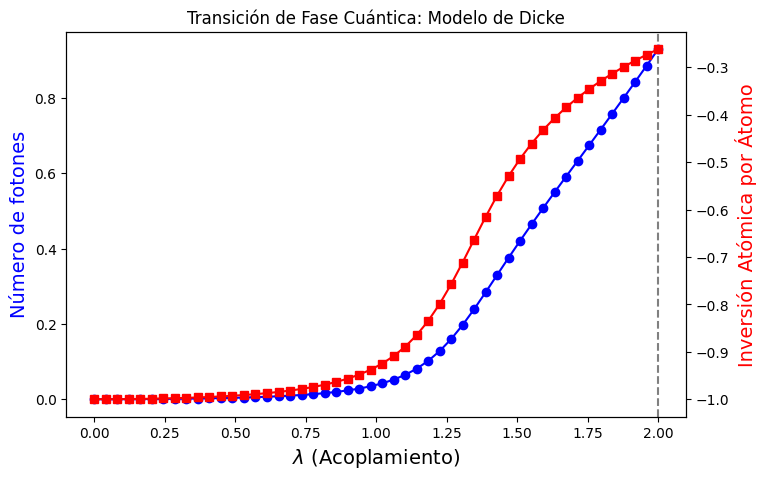

In [44]:
lamdas = np.linspace(0, 2, 50) # Rango de acoplamiento (debe cruzar lambda_c)

# Parte del Hamiltoniano que no depende de lambda
H0 = a.dag() * a + (epsilon / 2) * J_z

n_fotones = []
inversion = []

for l in lamdas:
    g_eff = l / (2 * np.sqrt(N_atomos))
    H = H0 + g_eff * (a  + a.dag()) * (J_p + J_m)
    
    # Calculamos el estado fundamental (energía y ket)
    en, gs = H.groundstate()
    
    # Guardamos los valores esperados en el estado fundamental
    n_fotones.append(expect(a.dag() * a, gs)/N_atomos)
    inversion.append(expect(J_z, gs) / N_atomos)

fig, ax1 = plt.subplots(figsize=(8, 5))

# Punto crítico teórico para el modelo de Dicke
lambda_c = 2* np.sqrt(epsilon) 
ax1.axvline(lambda_c, color='gray', linestyle='--', label='Punto Crítico')

ax1.plot(lamdas, n_fotones, 'bo-', label='Fotones')
ax1.set_xlabel(r'$\lambda$ (Acoplamiento)', fontsize=14)
ax1.set_ylabel('Número de fotones', color='b', fontsize=14)

ax2 = ax1.twinx()
ax2.plot(lamdas, inversion, 'rs-', label='Inversión (Jz/N)')
ax2.set_ylabel('Inversión Atómica por Átomo', color='r', fontsize=14)

plt.title("Transición de Fase Cuántica: Modelo de Dicke")
plt.show()

# 

# $J_+$

Para el estado inicial $|\psi_{0}\rangle = |0\rangle \otimes |j,+j\rangle$, el estado que tiene paridad definida

$$\Pi (|0\rangle \otimes |j,+j\rangle) = e^{\pi(n + j + m)} = e^{\pi(0 + j + j)} = \pm 1$$